# 06 — Model Evaluation and Explainability (Stages 9–10)

Reads the evaluation produced by the pipeline (`python -m ml.pipeline`): metrics, actual-vs-predicted, residuals,
error by product and weekday, recursive multi-day backtests, and permutation feature importance.

* **MAE**: average error in units/day. **RMSE**: punishes big misses. **WAPE**: total error / total demand.
* **MAPE**: only on days with ≥ 5 units (undefined for zero days). **R²**: diagnostic.

> **Colab:** run the setup cell; it asks for the project ZIP the first time. Put `Online Retail.xlsx` in `data/raw/` (or run notebook 01 first, which uploads it).

In [1]:
import sys, os, zipfile, io
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path.cwd()
for c in (ROOT, ROOT.parent, ROOT / "AI-Sales-Forecasting-Inventory"):
    if (c / "ml").is_dir():
        ROOT = c
        break
if IN_COLAB and not (ROOT / "ml").is_dir():
    from google.colab import files
    print("Upload the project ZIP once (AI-Sales-Forecasting-Inventory.zip):")
    for name, data in files.upload().items():
        zipfile.ZipFile(io.BytesIO(data)).extractall("/content")
    ROOT = Path("/content/AI-Sales-Forecasting-Inventory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["SFIO_PROJECT_ROOT"] = str(ROOT)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display, Markdown
from ml import config
config.ensure_directories()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
print("Project root:", ROOT.name, "| Colab:", IN_COLAB)

Project root: AI-Sales-Forecasting-Inventory | Colab: False


In [2]:
import json
ev = json.loads((config.REPORTS_DIR / "09_model_evaluation.json").read_text())
meta = json.loads((config.ARTIFACTS_DIR / "model_metadata.json").read_text())
print("Selected model:", meta["model_name"], "| rule:", meta["selection_rule"])
pd.DataFrame(ev["comparison"]).round(3)

Selected model: hist_gradient_boosting | rule: Lowest validation MAE among ML models (tuned with rolling-origin CV on training dates only).


,model,type,split,n,mae,rmse,wape_pct,mape_pct,mape_coverage_pct,r2,bias
0,baseline_previous_day,baseline,validation,21472,25.428,76.485,118.582,127.124,52.967,-0.576,-3.700
1,baseline_previous_day,baseline,test,20900,26.634,95.656,111.657,121.611,58.373,-0.595,-3.382
2,baseline_same_day_last_week,baseline,validation,21472,26.044,78.855,121.452,122.978,52.967,-0.675,-1.325
3,baseline_same_day_last_week,baseline,test,20900,26.254,91.155,110.063,126.254,58.373,-0.449,-0.757
4,baseline_moving_average_7,baseline,validation,21472,21.152,60.485,98.638,89.963,52.967,0.015,-3.940
5,baseline_moving_average_7,baseline,test,20900,21.226,71.675,88.987,88.690,58.373,0.104,-3.646
6,linear_regression,ml,validation,21472,19.312,57.368,90.058,76.637,52.967,0.114,-3.299
7,random_forest,ml,validation,21472,20.389,57.286,95.082,82.450,52.967,0.116,-0.415
8,hist_gradient_boosting,ml,validation,21472,18.424,58.527,85.918,63.499,52.967,0.077,-7.904
9,xgboost,ml,validation,21472,18.490,57.685,86.225,66.627,52.967,0.104,-5.652


In [3]:
pd.Series(ev["summary"])

best_model                hist_gradient_boosting
best_baseline          baseline_moving_average_7
test_mae_model                         21.274879
test_mae_baseline                      21.226459
mae_improvement_pct                    -0.228111
test_wape_model                        89.189965
test_wape_baseline                     88.986976
beats_baseline                             False
dtype: object

## Charts

### Actual vs predicted (test)

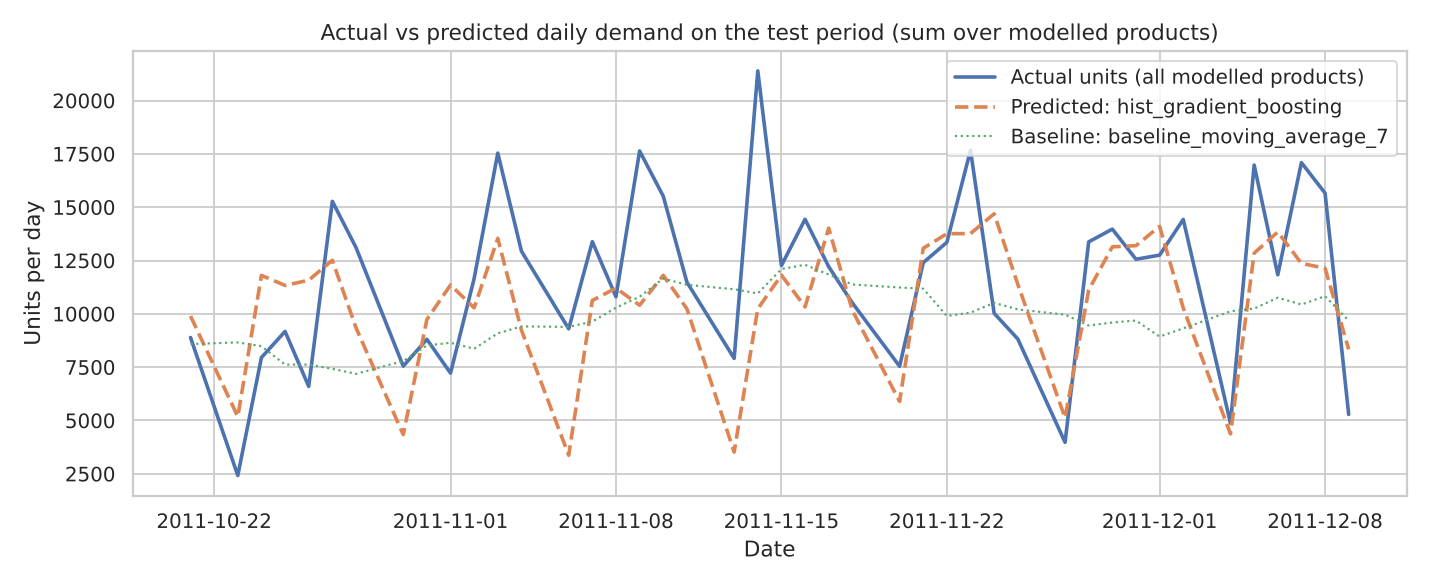

### Residual distribution

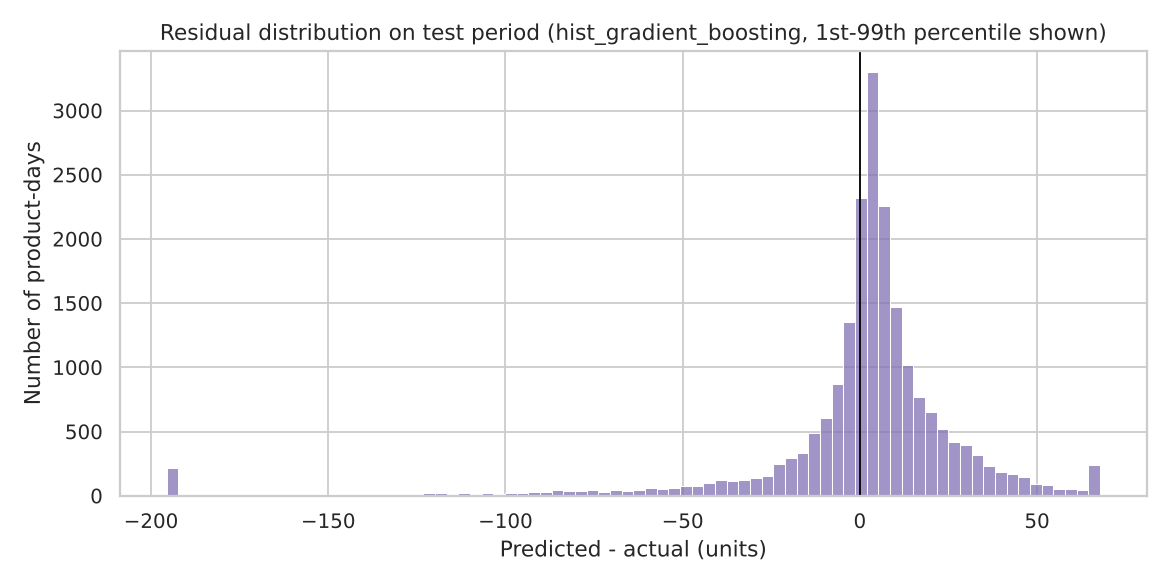

### Model comparison

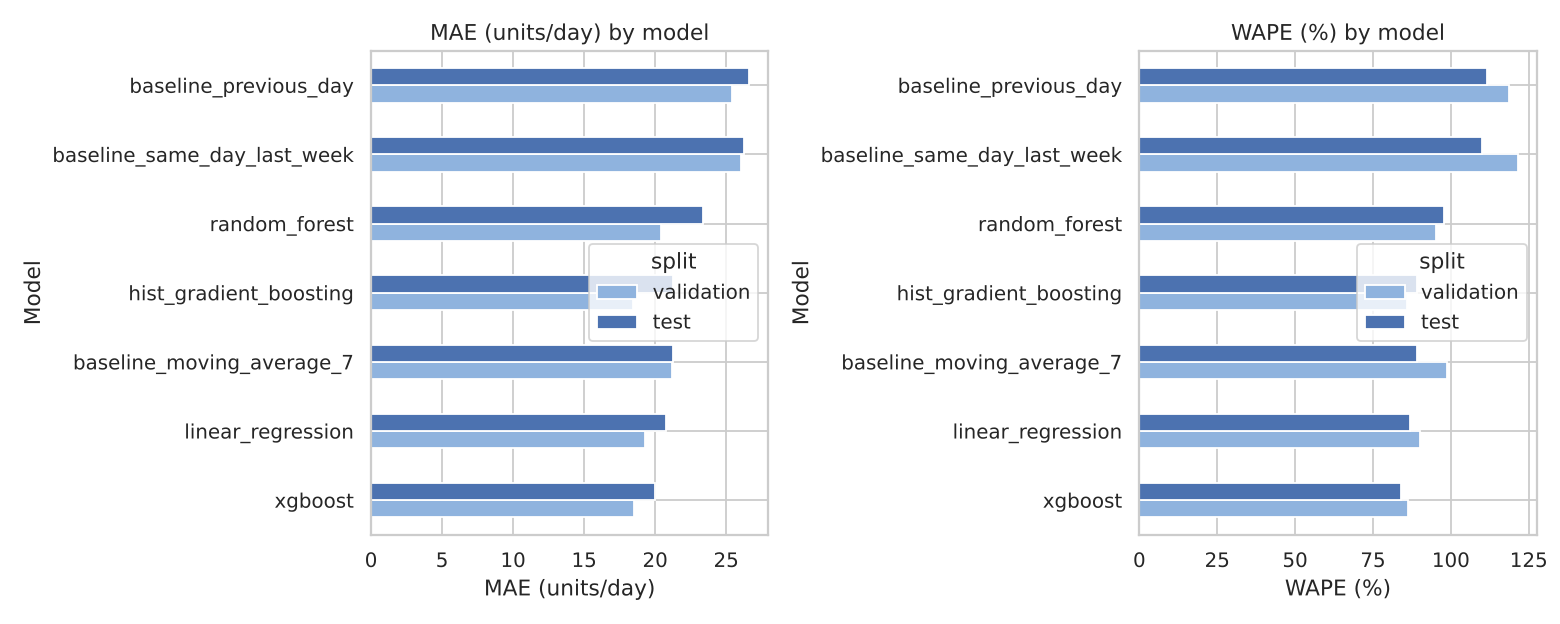

### Error by weekday

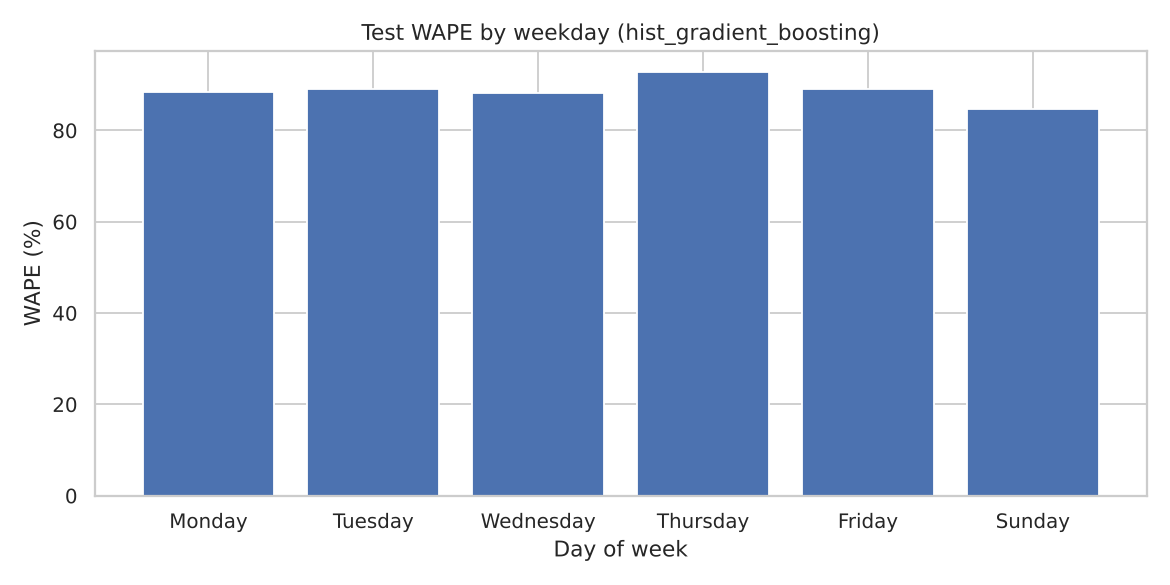

### Error by product

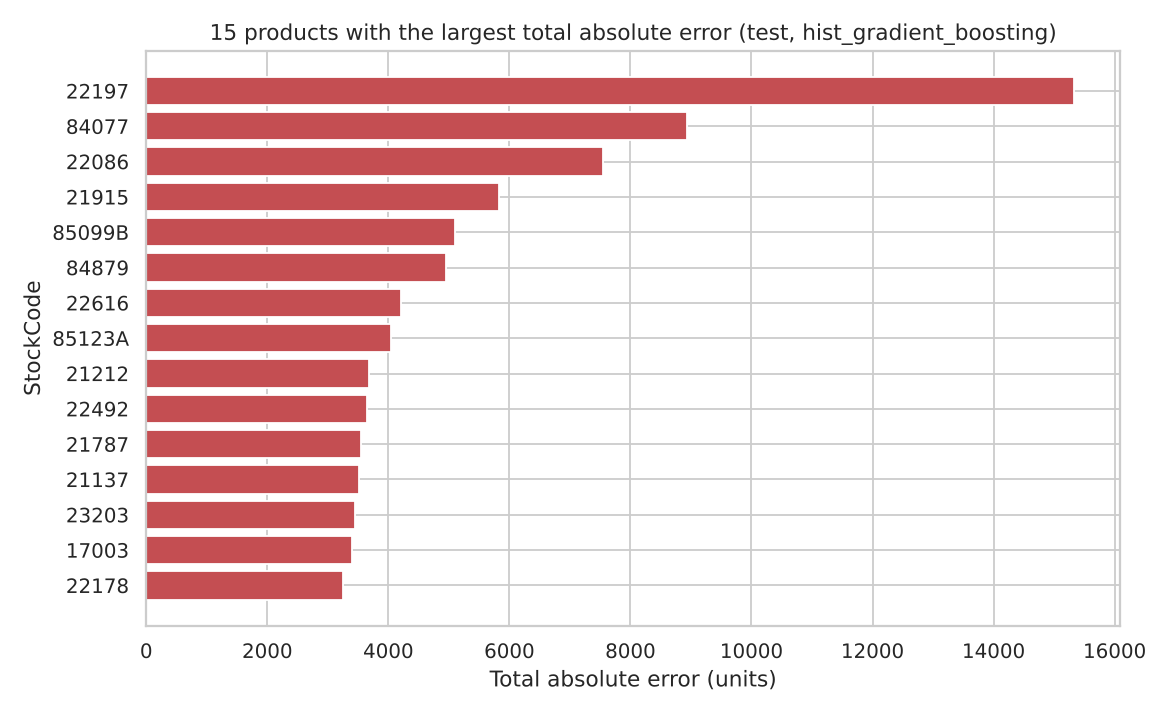

### Forecast accuracy by horizon

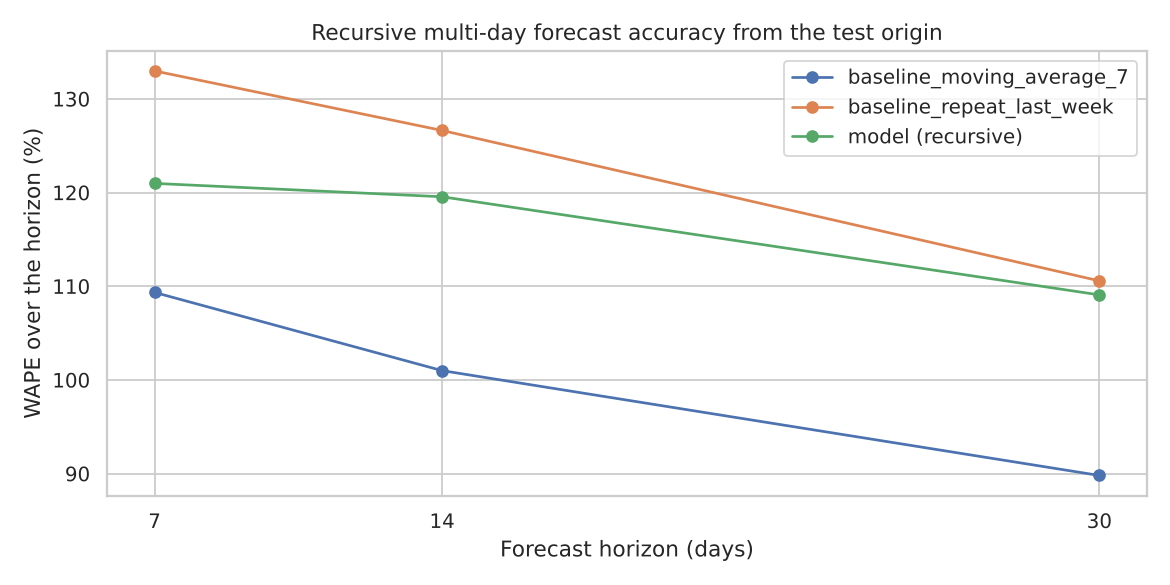

In [4]:
for c in ev["charts"]:
    display(Markdown(f"### {c['title']}"))
    display(Image(filename=str(config.REPORTS_DIR / c["file"]), width=900))

## Recursive forecasting backtests
Forecast 30 days recursively from a fixed origin using a model trained only on data before it.

In [5]:
print("Validation origin:", ev["recursive_backtest_validation_origin"])
display(pd.DataFrame(ev["recursive_backtest_validation"])[["horizon_days", "method", "mae", "wape_pct", "bias"]].round(2))
print("Test origin:", ev["recursive_backtest_origin"])
display(pd.DataFrame(ev["recursive_backtest"])[["horizon_days", "method", "mae", "wape_pct", "bias"]].round(2))

Validation origin: 2011-08-31T00:00:00


,horizon_days,method,mae,wape_pct,bias
0,7,model (recursive),17.82,87.55,-9.32
1,7,baseline_moving_average_7,18.15,89.16,-11.31
2,7,baseline_repeat_last_week,20.16,99.04,-9.81
3,14,model (recursive),17.68,86.98,-9.27
4,14,baseline_moving_average_7,18.04,88.74,-11.29
5,14,baseline_repeat_last_week,20.58,101.21,-9.78
6,30,model (recursive),18.60,85.81,-9.21
7,30,baseline_moving_average_7,19.27,88.88,-12.63
8,30,baseline_repeat_last_week,21.87,100.88,-10.72


Test origin: 2011-10-20T00:00:00


,horizon_days,method,mae,wape_pct,bias
0,7,model (recursive),20.42,120.98,5.81
1,7,baseline_moving_average_7,18.46,109.34,0.39
2,7,baseline_repeat_last_week,22.45,132.99,3.27
3,14,model (recursive),23.33,119.55,4.90
4,14,baseline_moving_average_7,19.71,100.99,-2.23
5,14,baseline_repeat_last_week,24.71,126.63,0.65
6,30,model (recursive),25.23,109.08,3.14
7,30,baseline_moving_average_7,20.77,89.80,-5.81
8,30,baseline_repeat_last_week,25.58,110.58,-3.06


## Error by weekday and product

In [6]:
display(pd.DataFrame(ev["error_by_weekday"]).round(2))
display(pd.DataFrame(ev["error_by_product_top20"]).head(10).round(2))

,day_of_week,mae,total_actual,total_abs_error,rows,wape_pct
0,Monday,24.32,94278.0,83455.97,3432,88.52
1,Tuesday,20.44,78610.0,70018.24,3426,89.07
2,Wednesday,25.25,97649.0,86227.63,3415,88.30
3,Thursday,27.02,98975.0,91874.61,3400,92.83
4,Friday,20.11,85469.0,76215.20,3790,89.17
5,Sunday,10.72,43556.0,36853.34,3437,84.61


,StockCode,mae,total_actual,total_abs_error,rows,wape_pct
0,22197,356.37,21524.0,15323.88,43,71.19
1,84077,207.72,11796.0,8932.02,43,75.72
2,22086,175.38,10832.0,7541.32,43,69.62
3,21915,142.09,5435.0,5825.88,41,107.19
4,85099B,118.57,7637.0,5098.32,43,66.76
5,84879,115.20,7522.0,4953.69,43,65.86
6,22616,97.79,4487.0,4205.01,43,93.72
7,85123A,94.22,6389.0,4051.27,43,63.41
8,21212,85.47,3741.0,3675.41,43,98.25
9,22492,86.82,4344.0,3646.32,42,83.94


## Explainability (permutation importance)

The hist_gradient_boosting model bases its forecast mainly on recent averages / volatility of demand (49% of total importance). rolling: 49%; history: 44%; price: 4%; calendar: 3%; lag: 0%.
- rolling_mean_28 (30.2% of importance): Mean daily units over D-28..D-1. Shuffling it raises test MAE by 3.92 units/day; higher values push the forecast UP (rank corr +0.86).
- hist_mean_demand (24.9% of importance): Average daily units over the product's whole history up to D-1. Shuffling it raises test MAE by 3.24 units/day; higher values push the forecast UP (rank corr +0.81).
- hist_std_demand (14.9% of importance): Standard deviation of daily units over the product's history up to D-1 (demand variability). Shuffling it raises test MAE by 1.94 units/day; higher values push the forecast UP (rank corr +0.72).
- rolling_mean_7 (6.2% of importance): Mean daily units over D-7..D-1 (shift(1) then rolling 7). Shuffling it raises test MAE by 0.80 units/day; higher values push the forecast UP (rank corr

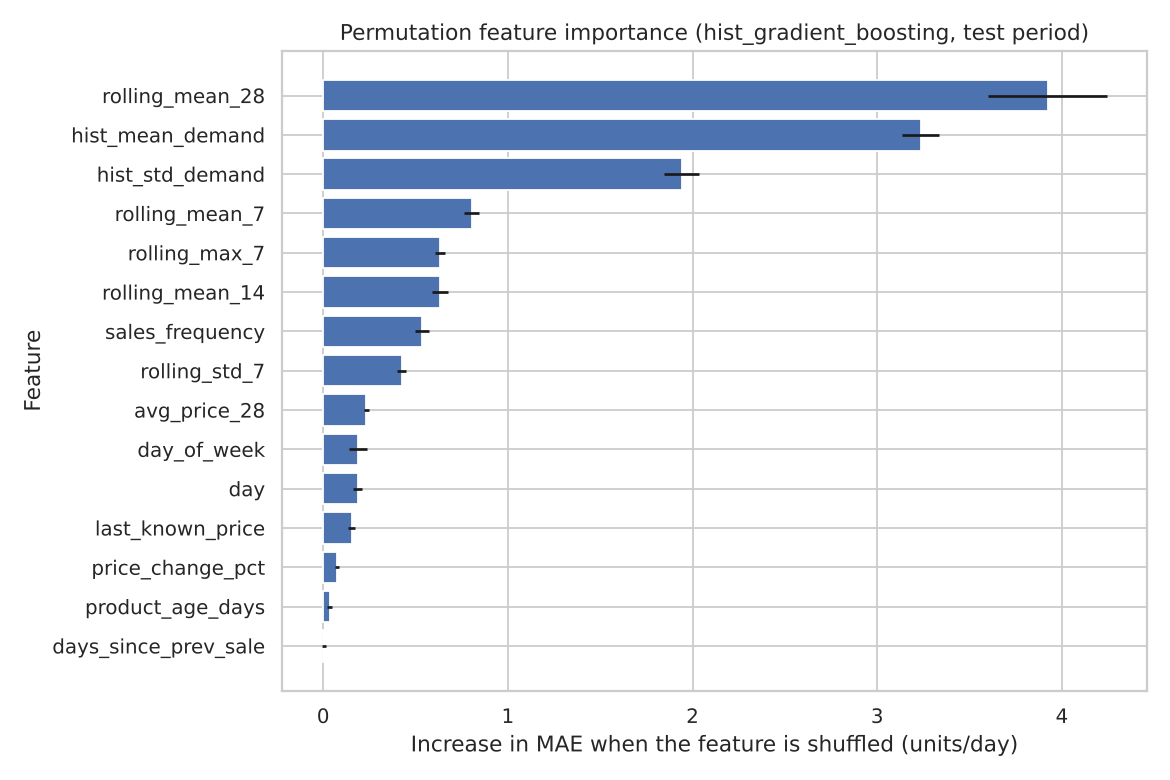

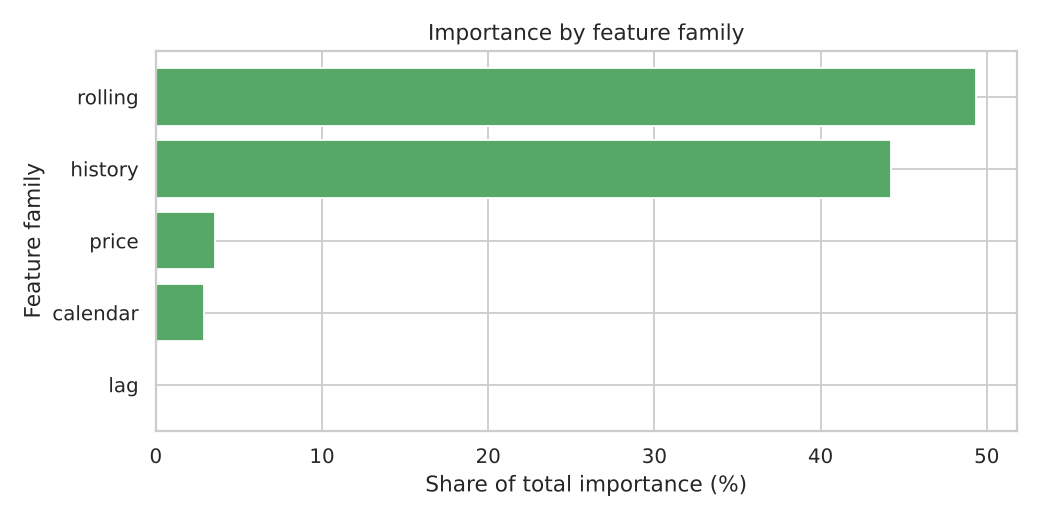

In [7]:
imp = json.loads((config.ARTIFACTS_DIR / "feature_importance.json").read_text())
print(imp["business_summary"])
for e in imp["top_feature_explanations"]:
    print("-", e)
display(Image(filename=str(config.FIGURES_DIR / "10_feature_importance.png"), width=750))
display(Image(filename=str(config.FIGURES_DIR / "10_feature_family_importance.png"), width=600))